# Chapter 10: Common Units Explain the Rules

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see why fractions and decimals can only be added when they count the same size of part. You will add fifths, find a common unit for thirds and fourths, add past one whole, and see why decimal points must line up.

A note before we start: the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight through like a book.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from matplotlib.patches import Rectangle

TEAL, GOLD, TERRA, NAVY, INK, GREY, LIGHT = "#1f7a80", "#c9a227", "#c4552d", "#1f3a5f", "#222222", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def frac(x):
    """Write a Fraction the plain way: 3/4, or 2 for a whole number."""
    x = Fraction(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def mixed(x):
    """Write a Fraction as a mixed number: 11/4 becomes 2 3/4."""
    x = Fraction(x)
    whole, rem = divmod(x.numerator, x.denominator)
    if rem == 0:
        return str(whole)
    if whole == 0:
        return f"{rem}/{x.denominator}"
    return f"{whole} {rem}/{x.denominator}"

def bare(ax):
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)

def strip(ax, y, parts, runs, height=0.62):
    """One whole drawn as equal cells. runs is a list of (start, stop, color)."""
    for k in range(parts):
        color = "white"
        for s, e, c in runs:
            if s <= k < e:
                color = c
        ax.add_patch(Rectangle((k/parts, y), 1/parts, height, facecolor=color,
                               edgecolor=GREY if color == "white" else "white", lw=1.1))
    ax.add_patch(Rectangle((0, y), 1, height, fill=False, edgecolor=INK, lw=1.3))

## 1. The denominator names the unit

**Question in plain words:** Why does $2/5 + 1/5$ keep the 5 on the bottom?

$$2/5 + 1/5 = 3/5 \qquad\qquad 2/5 + 1/5 \neq 3/10$$

**What the symbols mean:** The bottom number names the size of each part: fifths of one pan. The top number counts how many of those parts are present. We add $2/5 + 1/5$, then compare with the tempting (wrong) move of adding the bottoms too.

In [2]:
a, second = 2, 1
print("Unit of each piece: fifths")
print(f"count of fifths: {a} + {second} = {a+second}")
print(f"correct: {a}/5 + {second}/5 = {a+second}/5 = {(a+second)/5:.1f} of the pan")
print()
print("Wrong move (adding the bottoms too):")
print(f"  {a}/5 + {second}/5 = ({a} + {second})/(5 + 5) = {a+second}/10 = {(a+second)/10:.1f} of the pan")
print(f"  true total is {a+second}/5 = {(a+second)/5:.1f}, so the wrong answer falls short")

print()
print("Other second pieces:")
for s in [1, 2, 3]:
    print(f"  2/5 + {s}/5 = {2+s}/5 = {(2+s)/5:.1f}   (wrong: {2+s}/10 = {(2+s)/10:.1f})")

Unit of each piece: fifths
count of fifths: 2 + 1 = 3
correct: 2/5 + 1/5 = 3/5 = 0.6 of the pan

Wrong move (adding the bottoms too):
  2/5 + 1/5 = (2 + 1)/(5 + 5) = 3/10 = 0.3 of the pan
  true total is 3/5 = 0.6, so the wrong answer falls short

Other second pieces:
  2/5 + 1/5 = 3/5 = 0.6   (wrong: 3/10 = 0.3)
  2/5 + 2/5 = 4/5 = 0.8   (wrong: 4/10 = 0.4)
  2/5 + 3/5 = 5/5 = 1.0   (wrong: 5/10 = 0.5)


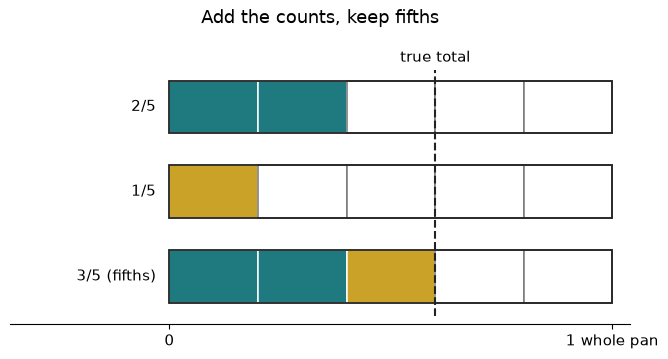

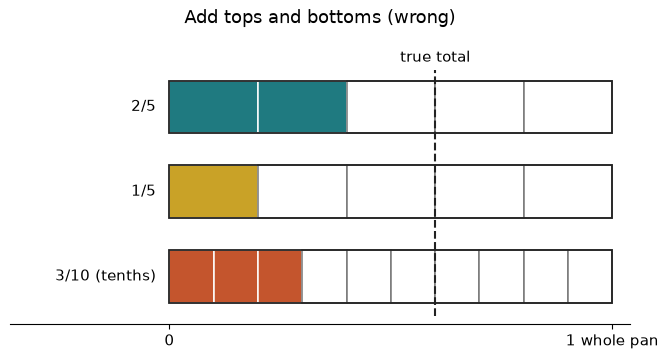

In [3]:
def fifths(second=1, rule="count"):
    a = 2
    total = Fraction(a + second, 5)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    strip(ax, 2.0, 5, [(0, a, TEAL)])
    strip(ax, 1.0, 5, [(0, second, GOLD)])
    if rule == "count":
        strip(ax, 0.0, 5, [(0, a, TEAL), (a, a+second, GOLD)]); bottom = f"{a+second}/5 (fifths)"
    else:
        strip(ax, 0.0, 10, [(0, a+second, TERRA)]); bottom = f"{a+second}/10 (tenths)"
    for y, t in [(2.0, "2/5"), (1.0, f"{second}/5"), (0.0, bottom)]:
        ax.text(-0.03, y+0.31, t, ha="right", va="center")
    ax.plot([float(total)]*2, [-0.15, 2.75], color=INK, ls="dashed")
    ax.text(float(total), 2.8, "true total", ha="center", va="bottom")
    ax.set_xlim(-0.36, 1.04); ax.set_ylim(-0.25, 3.2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1 whole pan"]); bare(ax)
    ax.set_title("Add the counts, keep fifths" if rule == "count" else "Add tops and bottoms (wrong)")
    plt.show()

fifths(1, "count")
fifths(1, "add_bottoms")

**What this shows:** When the bottom number stays 5, the count grows and the parts stay the same size, so the bar reaches the dashed line. When it becomes 10, every part shrinks to half its size, and the bar stops short.

**Where it stops working:** Both fractions must be parts of the same pan. One fifth of a small pan and one fifth of a large pan are not the same size, so matching bottoms alone would not be enough.

## 2. Thirds and fourths become twelfths

**Question in plain words:** A third and a fourth of the same pan: what common unit lets you add them?

$$1/3 + 1/4 \neq 2/7 \qquad 1/3 + 1/4 = 4/12 + 3/12 = 7/12 \qquad 1/3 + 1/4 = 8/24 + 6/24 = 14/24$$

**What the symbols mean:** $1/3$ and $1/4$ are parts of one pan. $4/12$ and $3/12$ are the same parts cut finer, so both count twelfths. A common unit must fit evenly inside both a third and a fourth.

In [4]:
d = 12
t, f = d // 3, d // 4
print(f"1/3 in twelfths: (1 x {t})/(3 x {t}) = {t}/{d}")
print(f"1/4 in twelfths: (1 x {f})/(4 x {f}) = {f}/{d}")
print(f"sum: {t}/{d} + {f}/{d} = {t+f}/{d}")
print(f"simplest name: {frac(Fraction(t+f, d))} (decimal {(t+f)/d:.3f})")

print()
print("The tempting wrong answer, sevenths:")
print(f"  (1 + 1)/(3 + 4) = 2/7 = {2/7:.3f} of the pan, but the true sum is 7/12 = {7/12:.3f}")
print("  7 / 3 and 7 / 4 are not whole numbers, so thirds and fourths cannot be cut into sevenths")

print()
d = 24
t, f = d // 3, d // 4
print(f"Twenty-fourths: 1/3 = (1 x {t})/(3 x {t}) = {t}/{d}, 1/4 = (1 x {f})/(4 x {f}) = {f}/{d}")
print(f"  {t}/{d} + {f}/{d} = {t+f}/{d} = {frac(Fraction(t+f, d))} (divide top and bottom by 2)")

1/3 in twelfths: (1 x 4)/(3 x 4) = 4/12
1/4 in twelfths: (1 x 3)/(4 x 3) = 3/12
sum: 4/12 + 3/12 = 7/12
simplest name: 7/12 (decimal 0.583)

The tempting wrong answer, sevenths:
  (1 + 1)/(3 + 4) = 2/7 = 0.286 of the pan, but the true sum is 7/12 = 0.583
  7 / 3 and 7 / 4 are not whole numbers, so thirds and fourths cannot be cut into sevenths

Twenty-fourths: 1/3 = (1 x 8)/(3 x 8) = 8/24, 1/4 = (1 x 6)/(4 x 6) = 6/24
  8/24 + 6/24 = 14/24 = 7/12 (divide top and bottom by 2)


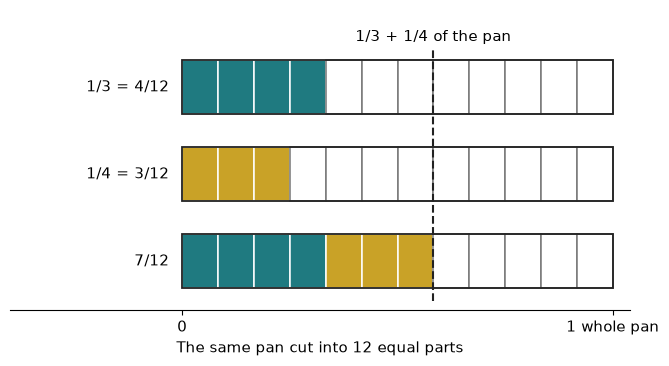

In [5]:
def common_unit(d=12):
    total = Fraction(1, 3) + Fraction(1, 4)
    t, f = d // 3, d // 4
    fig, ax = plt.subplots(figsize=(8, 3.9))
    strip(ax, 2.0, d, [(0, t, TEAL)])
    strip(ax, 1.0, d, [(0, f, GOLD)])
    strip(ax, 0.0, d, [(0, t, TEAL), (t, t+f, GOLD)])
    for y, text in zip([2.0, 1.0, 0.0], [f"1/3 = {t}/{d}", f"1/4 = {f}/{d}", f"{t+f}/{d}"]):
        ax.text(-0.03, y+0.31, text, ha="right", va="center")
    ax.plot([float(total)]*2, [-0.15, 2.75], color=INK, ls="dashed")
    ax.text(float(total), 2.8, "1/3 + 1/4 of the pan", ha="center", va="bottom")
    ax.set_xlim(-0.4, 1.04); ax.set_ylim(-0.25, 3.2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1 whole pan"])
    ax.set_xlabel(f"The same pan cut into {d} equal parts"); bare(ax)
    plt.show()

common_unit(12)

**What this shows:** Twelfths fit evenly inside both a third (4 per third) and a fourth (3 per fourth). Once both count twelfths, we add the counts: $4 + 3 = 7$. Twenty-fourths also work and land on the same place; sevenths do not fit either one, which is why $2/7$ is wrong.

**Where it stops working:** Both pieces must come from the same pan. Any common multiple of 3 and 4 works, and the smallest keeps the counts short.

## 3. A sum that passes one whole

**Question in plain words:** What happens when two pieces of the same pan add up to more than the pan?

$$3/4 + 2/3 = 9/12 + 8/12 = 17/12$$

**What the symbols mean:** $3/4$ and $2/3$ are parts of one whole. $9/12$ and $8/12$ are the same amounts in twelfths. $17/12$ counts seventeen twelfths, which is more than twelve.

In [6]:
fourths, thirds = 3, 2
na, nb = fourths * 3, thirds * 4
print(f"{fourths}/4 in twelfths: ({fourths} x 3)/(4 x 3) = {na}/12")
print(f"{thirds}/3 in twelfths: ({thirds} x 4)/(3 x 4) = {nb}/12")
print(f"sum: {na}/12 + {nb}/12 = {na+nb}/12")
w, r = divmod(na + nb, 12)
print(f"{na+nb} = {w} x 12 + {r}, so {na+nb}/12 = 12/12 + {r}/12 = {w} {r}/12")
print("past 1? yes")

print()
print("Other menu values (sum in twelfths):")
for fo in [1, 2, 3]:
    for th in [1, 2]:
        a, b = fo*3, th*4
        w, r = divmod(a+b, 12)
        txt = f"{w} {r}/12" if w else "below 1"
        print(f"  {fo}/4 + {th}/3 = {a}/12 + {b}/12 = {a+b}/12  ({txt})")

3/4 in twelfths: (3 x 3)/(4 x 3) = 9/12
2/3 in twelfths: (2 x 4)/(3 x 4) = 8/12
sum: 9/12 + 8/12 = 17/12
17 = 1 x 12 + 5, so 17/12 = 12/12 + 5/12 = 1 5/12
past 1? yes

Other menu values (sum in twelfths):
  1/4 + 1/3 = 3/12 + 4/12 = 7/12  (below 1)
  1/4 + 2/3 = 3/12 + 8/12 = 11/12  (below 1)
  2/4 + 1/3 = 6/12 + 4/12 = 10/12  (below 1)
  2/4 + 2/3 = 6/12 + 8/12 = 14/12  (1 2/12)
  3/4 + 1/3 = 9/12 + 4/12 = 13/12  (1 1/12)
  3/4 + 2/3 = 9/12 + 8/12 = 17/12  (1 5/12)


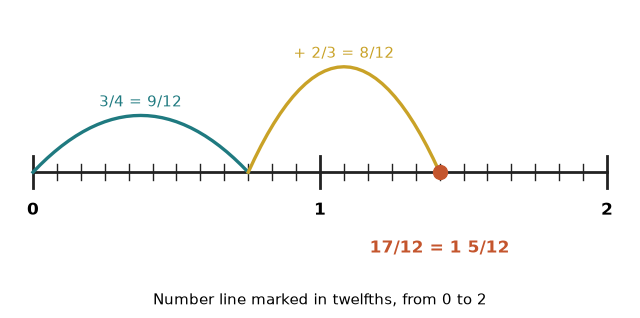

In [7]:
def past_one(fourths=3, thirds=2):
    a = Fraction(fourths, 4)
    na, nb = fourths*3, thirds*4
    total = Fraction(na + nb, 12)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot([0, 2], [0, 0], color=INK, lw=2)
    for k in range(25):
        major = k % 12 == 0
        ax.plot([k/12]*2, [-0.12, 0.12] if major else [-0.06, 0.06], color=INK, lw=2 if major else 1)
    for w in range(3):
        ax.text(w, -0.22, str(w), ha="center", va="top", fontsize=12, fontweight="bold")
    def hop(x0, x1, color, h, text):
        t = np.linspace(0, 1, 31)
        ax.plot(x0 + (x1-x0)*t, h*4*t*(1-t), color=color, lw=2.4)
        ax.text((x0+x1)/2, h+0.04, text, ha="center", va="bottom", color=color)
    hop(0, float(a), TEAL, 0.42, f"{fourths}/4 = {na}/12")
    hop(float(a), float(total), GOLD, 0.78, f"+ {thirds}/3 = {nb}/12")
    ax.plot([float(total)], [0], "o", color=TERRA, ms=10, zorder=5)
    w, r = divmod(na + nb, 12)
    ax.text(float(total), -0.5, f"{na+nb}/12" + (f" = {w} {r}/12" if total > 1 else ""), ha="center",
            va="top", fontsize=12, color=TERRA, fontweight="bold")
    ax.set_xlim(-0.08, 2.08); ax.set_ylim(-0.85, 1.2); ax.set_xticks([])
    ax.set_xlabel("Number line marked in twelfths, from 0 to 2")
    ax.spines["bottom"].set_visible(False); bare(ax); plt.show()

past_one(3, 2)

**What this shows:** The first hop is the first fraction in twelfths. The second hop starts where the first ended and moves right by the second fraction in twelfths. The dot is the sum, $17/12 = 1\frac{5}{12}$.

**Where it stops working:** Both fractions must be parts of equal wholes, and the line must be marked in equal twelfths. A sum above 1 is a valid amount, not a mistake.

## 4. Decimal places are common units too

**Question in plain words:** Why do decimal points have to line up when you add?

$$0.3 = 3/10 = 30/100 \qquad\qquad 0.35 + 0.20 = 35/100 + 20/100 = 55/100$$

**What the symbols mean:** The first place after the point counts tenths, the second counts hundredths. One tenth is a row of ten hundredth squares.

In [8]:
first, second = 35, 20          # in hundredths: 0.35 and 0.20
def dec(h):
    return f"{h//100}.{h%100:02d}"
t1, h1 = divmod(first, 10)
t2, h2 = divmod(second, 10)
total = first + second
print(f"0.35 by place: {t1} tenths + {h1} hundredths = {first}/100")
print(f"0.20 by place: {t2} tenths + {h2} hundredths = {second}/100")
print(f"sum in hundredths: {first} + {second} = {total}")
print(f"sum as a decimal: {total}/100 = {dec(total)}")
print(f"tenths meet tenths ({t1} + {t2} = {t1+t2}), hundredths meet hundredths ({h1} + {h2} = {h1+h2})")

print()
print("Other menu values:")
for f in [35, 30]:
    for s in [5, 20, 65]:
        print(f"  {dec(f)} + {dec(s)} = {f}/100 + {s}/100 = {f+s}/100 = {dec(f+s)}")

0.35 by place: 3 tenths + 5 hundredths = 35/100
0.20 by place: 2 tenths + 0 hundredths = 20/100
sum in hundredths: 35 + 20 = 55
sum as a decimal: 55/100 = 0.55
tenths meet tenths (3 + 2 = 5), hundredths meet hundredths (5 + 0 = 5)

Other menu values:
  0.35 + 0.05 = 35/100 + 5/100 = 40/100 = 0.40
  0.35 + 0.20 = 35/100 + 20/100 = 55/100 = 0.55
  0.35 + 0.65 = 35/100 + 65/100 = 100/100 = 1.00
  0.30 + 0.05 = 30/100 + 5/100 = 35/100 = 0.35
  0.30 + 0.20 = 30/100 + 20/100 = 50/100 = 0.50
  0.30 + 0.65 = 30/100 + 65/100 = 95/100 = 0.95


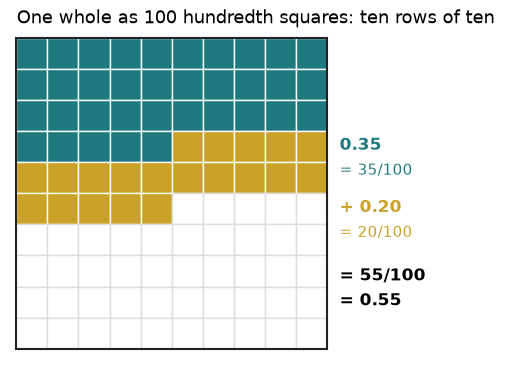

In [9]:
def decimal_grid(first=35, second=20):
    total = first + second
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for k in range(100):
        r, c = divmod(k, 10)
        color = TEAL if k < first else (GOLD if k < total else "white")
        ax.add_patch(Rectangle((c, 9-r), 1, 1, facecolor=color, edgecolor="white" if color != "white" else LIGHT))
    ax.add_patch(Rectangle((0, 0), 10, 10, fill=False, edgecolor=INK, lw=1.5))
    ax.text(10.4, 6.4, f"0.{first}", color=TEAL, fontweight="bold", fontsize=12)
    ax.text(10.4, 5.6, f"= {first}/100", color=TEAL)
    ax.text(10.4, 4.4, f"+ 0.{second:02d}", color=GOLD, fontweight="bold", fontsize=12)
    ax.text(10.4, 3.6, f"= {second}/100", color=GOLD)
    ax.text(10.4, 2.2, f"= {total}/100", fontweight="bold", fontsize=12)
    ax.text(10.4, 1.4, f"= {total//100}.{total%100:02d}", fontweight="bold", fontsize=12)
    ax.set_xlim(-0.2, 15.6); ax.set_ylim(-0.2, 10.2); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("One whole as 100 hundredth squares: ten rows of ten")
    plt.show()

decimal_grid(35, 20)

**What this shows:** Each decimal is turned into hundredths and shaded in the grid: 35 squares, then 20 more, 55 in all. Lining up the points makes tenths meet tenths and hundredths meet hundredths, which is why column-by-column addition works.

**Where it stops working:** We used decimals with at most two places, so every number is a whole count of hundredths. Lining up the right-hand digits instead of the points would add tenths to hundredths.

## Practice

**1.** What is $3/8 + 4/8$, and why is the answer not $7/16$?

<details><summary>Show answer</summary>

Both count eighths: $3 + 4 = 7$ eighths, so $7/8$. The answer $7/16$ would be 7 sixteenth-sized parts, half as much pan.
</details>

**2.** Add $5/6 + 3/8$ using twenty-fourths.

<details><summary>Show answer</summary>

$5/6 = (5 \times 4)/(6 \times 4) = 20/24$ and $3/8 = (3 \times 3)/(8 \times 3) = 9/24$. Then $20/24 + 9/24 = 29/24 = 24/24 + 5/24 = 1\frac{5}{24}$.
</details>

**3.** Add $3/4 + 1/3$ and write the result as a mixed number.

<details><summary>Show answer</summary>

$3/4 = 9/12$ and $1/3 = 4/12$, so $9/12 + 4/12 = 13/12 = 12/12 + 1/12 = 1\frac{1}{12}$.
</details>

**4.** Add $0.4 + 0.25$ by renaming both in hundredths.

<details><summary>Show answer</summary>

$0.4 = 40/100$ and $0.25 = 25/100$, so $40/100 + 25/100 = 65/100 = 0.65$.
</details>